# Etapa 2: análise exploratória da base final

Entrada: `data/processed/chembl_4targets.csv`, gerado por `01_curadoria.ipynb`. As decisões continuam a numeração da etapa 1 (D7 em diante) e estão resumidas na seção 10.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from src import eda, plots
from src.config import FINAL_CSV

plots.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

final = pd.read_csv(FINAL_CSV)
print("formato:", final.shape)
final.head()

formato: (27714, 9)


,ChEMBL ID,SMILES,Molecular Weight,LogP,HBA,HBD,TPSA,pChEMBL,Protein
0,CHEMBL100203,Cc1sc(C)c2c1SCc1cnn(C)c1-2,236.37,3.37,4.0,0.0,17.82,6.96,DRD2
1,CHEMBL100454,CN1CCN(C2=Nc3ccccc3Nc3sc(CO)cc32)CC1,328.44,2.62,6.0,2.0,51.10,7.66,DRD2
2,CHEMBL10085,CC(C)Oc1ccccc1N1CCN(Cc2cccc(C(=O)N3CCCCC3)c2)CC1,421.59,4.42,4.0,0.0,36.02,8.66,DRD2
3,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,346.82,5.01,4.0,1.0,50.70,6.34,EGFR
4,CHEMBL101285,Oc1ccccc1OCCNCc1ccccc1,243.31,2.56,3.0,2.0,41.49,6.34,DRD2


## 1. Distribuição das classes

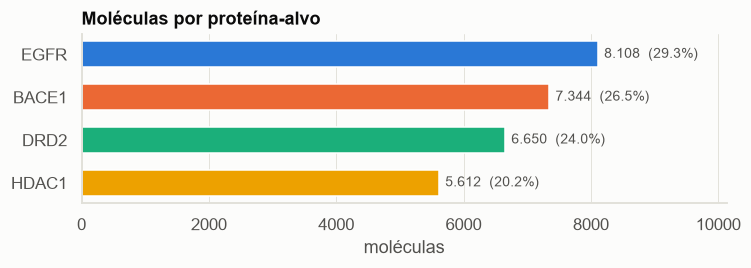

In [2]:
plots.class_counts(final)

Classes balanceadas: chutar sempre a majoritária (EGFR) acerta cerca de 29%.

## 2. Valores faltantes

In [3]:
for table in eda.missing_summary(final):
    display(table)

linhas com descritor faltante: 238 (0.86%)


,Molecular Weight,LogP,HBA,HBD,TPSA
faltantes,0,238,238,238,238


,linhas com faltante
Protein,
EGFR,49
BACE1,30
DRD2,116
HDAC1,43


,count,mean,std,min,25%,50%,75%,max
Molecular Weight das linhas com faltante,238.0,1226.5,635.9,277.5,1003.3,1102.8,1489.6,3771.3


As linhas sem descritor são moléculas grandes (mediana acima de 1.000 Da), para as quais o ChEMBL não calcula propriedades. São menos de 1% da base.

> **D7.** Manter essas linhas no CSV final e removê-las na modelagem (`eda.complete_rows`), sem imputação.

In [4]:
complete = eda.complete_rows(final)
print("linhas completas:", len(complete))

linhas completas: 27476


## 3. Estatísticas descritivas

In [5]:
eda.describe_features(final)

,count,mean,std,min,25%,50%,75%,max
Molecular Weight,27714.0,469.20,135.65,127.14,398.22,453.63,518.68,3771.26
LogP,27476.0,4.02,1.38,-3.83,3.13,3.98,4.85,14.00
HBA,27476.0,6.11,2.11,0.00,5.00,6.00,7.00,18.00
HBD,27476.0,2.07,1.35,0.00,1.00,2.00,3.00,13.00
TPSA,27476.0,90.35,36.32,3.24,67.40,89.60,110.77,404.94
pChEMBL,27714.0,7.32,0.87,6.00,6.61,7.21,7.92,11.00


In [6]:
eda.medians_by_class(final)

,Molecular Weight,LogP,HBA,HBD,TPSA,pChEMBL
Protein,,,,,,
EGFR,497.60,4.60,7.0,2.0,97.84,7.48
BACE1,452.93,3.41,6.0,2.0,99.55,7.35
DRD2,434.46,4.13,5.0,1.0,54.46,6.95
HDAC1,430.44,3.68,6.0,3.0,100.55,7.04


## 4. Distribuição das features por classe

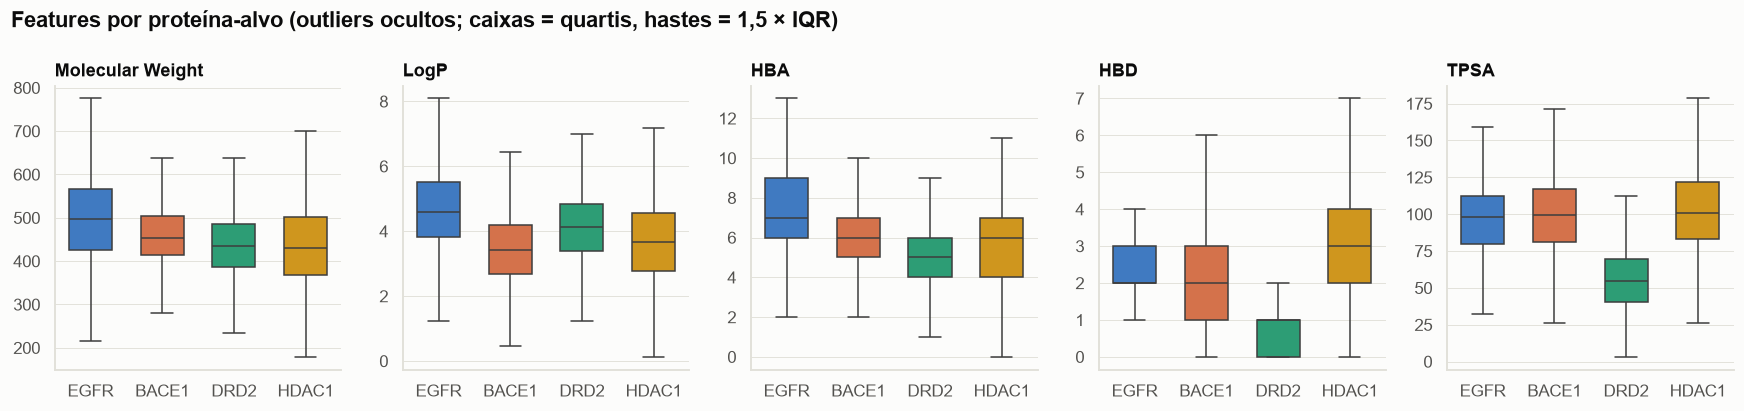

In [7]:
plots.feature_boxplots(final)

- **DRD2**: `TPSA` e `HBD` baixos.
- **EGFR**: moléculas mais pesadas, lipofílicas e com mais `HBA`.
- **HDAC1**: maior `HBD`.
- **BACE1** e **HDAC1**: sobrepostas em massa, `TPSA` e `HBA`.

## 5. Poder de separação de cada feature

Árvore de profundidade 3 com uma única feature, em validação cruzada de 5 partes. É um diagnóstico, não o modelo final.

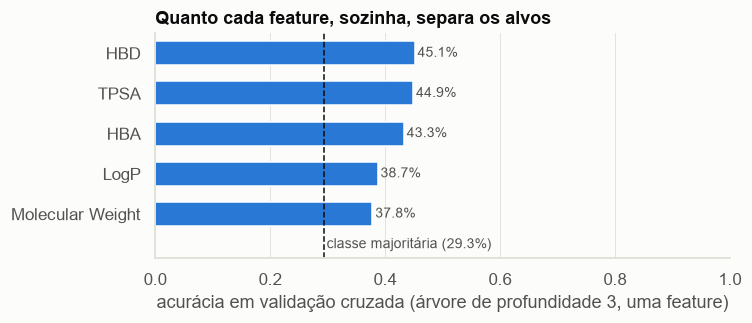

In [8]:
accuracy, baseline = eda.single_feature_accuracy(final)
plots.single_feature_accuracy(accuracy, baseline)

Toda feature supera a classe majoritária (cerca de 29%), mas nenhuma passa de 45%. A árvore vai precisar combinar features.

## 6. Correlação entre features

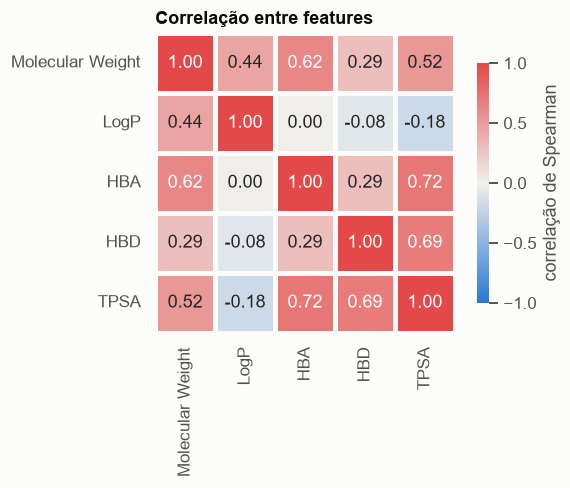

In [9]:
plots.correlation_heatmap(complete)

`TPSA`, `HBA` e `HBD` são correlacionadas (todas medem polaridade). Isso não atrapalha a árvore, mas divide a importância entre elas.

## 7. Espaço LogP × TPSA

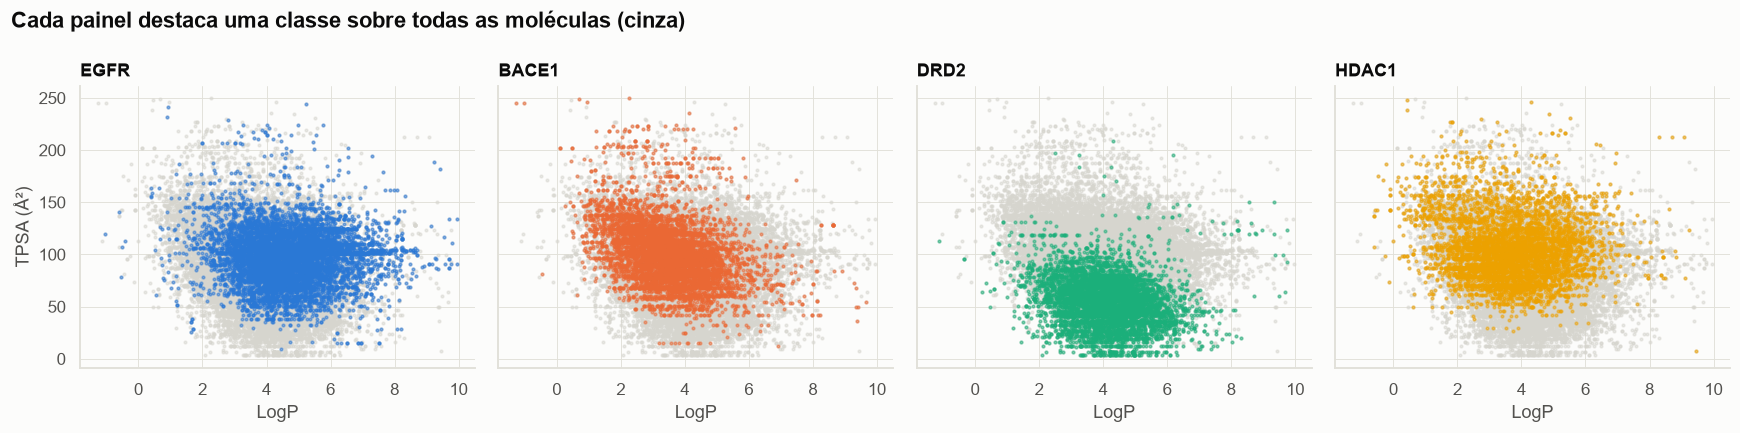

In [10]:
plots.logp_tpsa_by_class(complete)

DRD2 concentra-se em TPSA baixa e EGFR em LogP alto. BACE1 e HDAC1 ocupam a mesma região.

## 8. Duplicatas e outliers

In [11]:
eda.duplicates_and_outliers(final)

,linhas
ChEMBL ID duplicado,0
SMILES duplicado,1
linhas que repetem os 5 descritores de outra,4777
grupos de descritores idênticos com classes diferentes,0
Molecular Weight > 1.000 Da,182
LogP > 8,182


In [12]:
eda.duplicated_smiles(final)

,ChEMBL ID,SMILES,Molecular Weight,LogP,HBA,HBD,TPSA,pChEMBL,Protein
5915,CHEMBL3260841,COC1CCC2(CC1)Cc1ccc(-c3cccc(C#N)c3)cc1C21N=C(N)N(C)C1=O,414.51,3.34,5.0,1.0,91.71,8.4,BACE1
7906,CHEMBL3652433,COC1CCC2(CC1)Cc1ccc(-c3cccc(C#N)c3)cc1C21N=C(N)N(C)C1=O,414.51,3.34,5.0,1.0,91.71,8.4,BACE1


Nenhum ID duplicado e um único SMILES repetido (mesma classe). Descritores idênticos nunca aparecem em classes diferentes. Os outliers são moléculas reais, e a árvore é robusta a eles.

> **D8.** Não remover outliers nem descritores repetidos.

## 9. Potência por classe

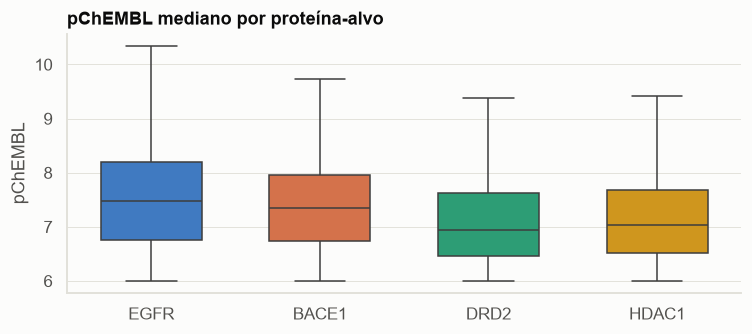

In [13]:
plots.pchembl_by_class(final)

> **D9.** `pChEMBL` não entra como feature: é o resultado do ensaio contra o alvo.

## 10. Resumo das decisões

| ID | Decisão |
|---|---|
| D7 | Remover linhas sem descritor só na modelagem |
| D8 | Manter outliers e descritores repetidos |
| D9 | Não usar `pChEMBL` como feature |

Base para modelagem: as linhas completas de `chembl_4targets.csv` (`eda.complete_rows`). Features: `Molecular Weight`, `LogP`, `HBA`, `HBD`, `TPSA`. Alvo: `Protein`.